In [13]:
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats


df_raw = pd.read_csv('final4.csv')

## Подготовка данных

In [15]:
df = df_raw.copy()

df = df.drop(columns=["Unnamed: 0"], errors="ignore")

if "category" in df.columns:
    category_values = set(df["category"].dropna().unique())
    expected = {"Desktop", "Laptop"}
    df["category"] = df["category"].map({"Desktop": 0, "Laptop": 1})

target = "cpu_mark"

features = [c for c in df.columns if c != target]

non_numeric = df[features + [target]].select_dtypes(exclude=np.number).columns.tolist()
print("Кодировка category: Desktop = 0, Laptop = 1")

Кодировка category: Desktop = 0, Laptop = 1


In [12]:
all_numeric = features + [target]

binary_columns = [
    c for c in all_numeric
    if df[c].dropna().nunique() <= 2
]

qq_columns = [
    c for c in all_numeric
    if c not in binary_columns and df[c].dropna().nunique() > 2
]

print("Q–Q plots будут построены для:")
print(qq_columns)

Q–Q plots будут построены для:
['cores', 'threads', 'base_clock_ghz', 'tdp_w', 'l2_cache_mb', 'l3_cache_mb', 'years_ago', 'cpu_mark_log']


In [4]:
import numpy as np
df['cpu_mark_log'] = np.log(df['cpu_mark'] + 1)

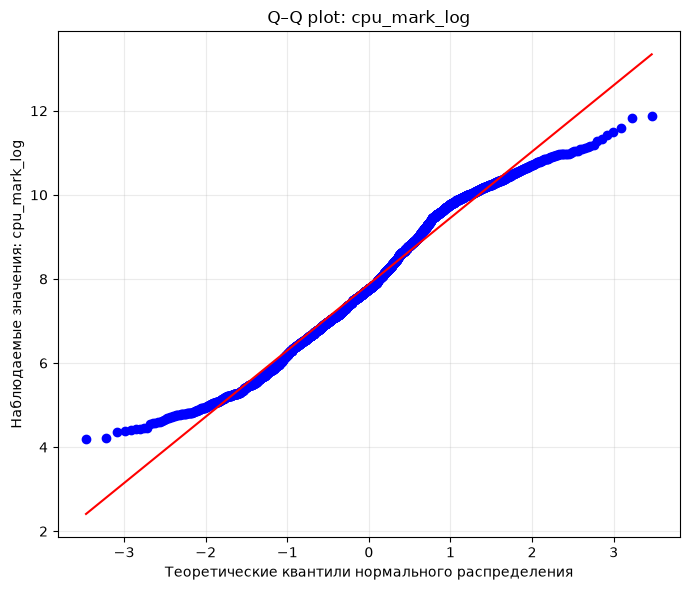

In [5]:
for col in ['cpu_mark_log']:
    values = df[col].dropna().astype(float)

    plt.figure(figsize=(7, 6))
    stats.probplot(values, dist="norm", plot=plt)
    plt.title(f"Q–Q plot: {col}")
    plt.xlabel("Теоретические квантили нормального распределения")
    plt.ylabel(f"Наблюдаемые значения: {col}")
    plt.grid(True, alpha=0.25)
    plt.tight_layout()
    plt.show()


In [16]:
df.head()

,category,cores,threads,base_clock_ghz,tdp_w,l2_cache_mb,l3_cache_mb,cpu_mark,years_ago,manufacturer_Apple,manufacturer_Intel,manufacturer_Other,manufacturer_Qualcomm,specs_missing_count
0,0,1,1.0,1.7,70.0,0.250,0.0,195,17,0,0,0,0,1
1,0,16,24.0,1.4,35.0,14.000,30.0,28964,4,0,1,0,0,0
2,1,4,8.0,2.4,47.0,1.000,6.0,5566,13,0,1,0,0,0
3,1,2,2.0,2.0,31.0,1.000,2.0,645,17,0,0,0,0,1
4,1,1,1.0,1.2,9.0,0.125,0.0,112,15,0,0,1,0,2


In [18]:
import seaborn as sns

<Axes: xlabel='cpu_mark', ylabel='Count'>

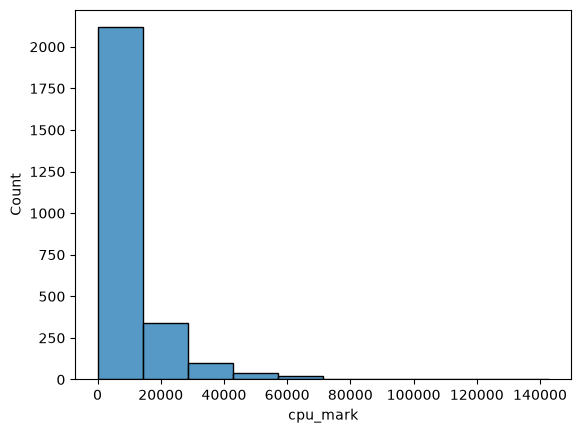

In [46]:
df['cpu_mark_log'] = np.log(df['cpu_mark'])
df_laptop = df[df['category'] == 1]
sns.histplot(data=df['cpu_mark'], bins=10)

<Axes: xlabel='cpu_mark', ylabel='Count'>

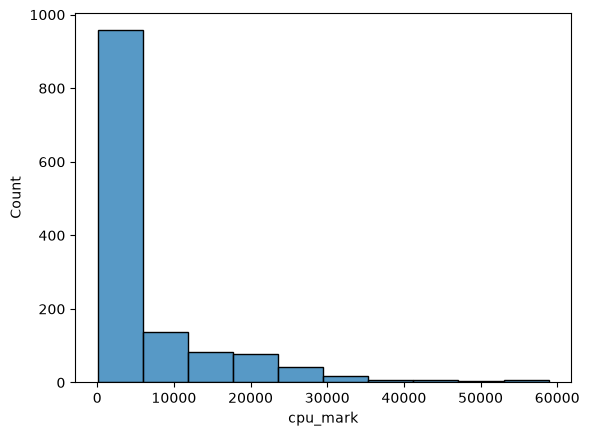

In [47]:
sns.histplot(data=df_laptop['cpu_mark'], bins=10)

In [40]:
pair_count = len(features) * (len(features) - 1) // 2
print(f"Число признаков: {len(features)}")
print(f"Будет построено отдельных графиков признак↔признак: {pair_count}")


Число признаков: 7
Будет построено отдельных графиков признак↔признак: 21


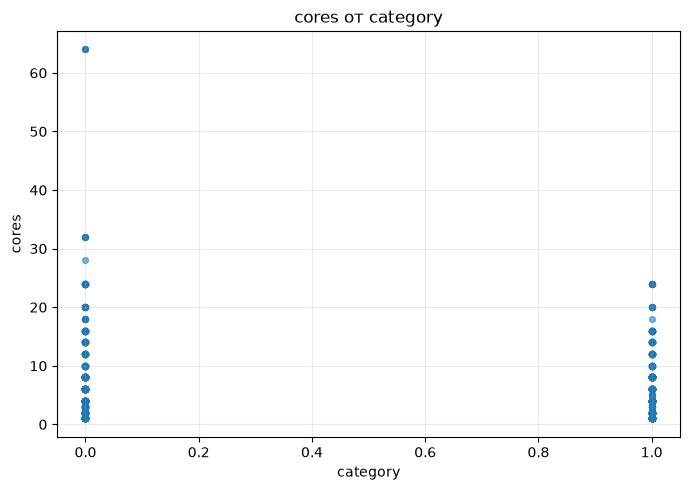

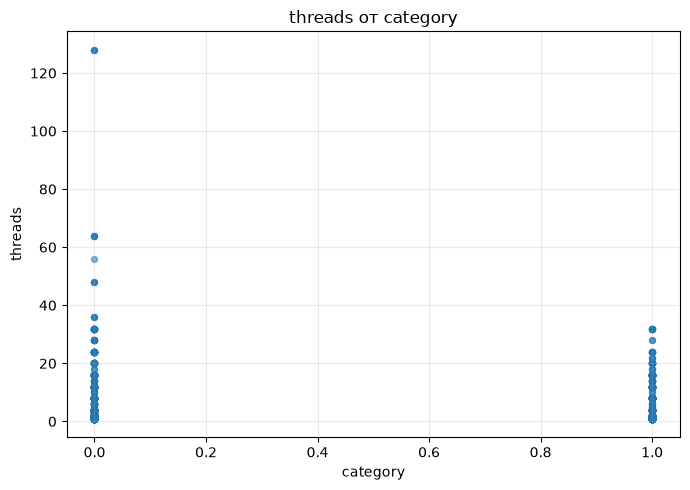

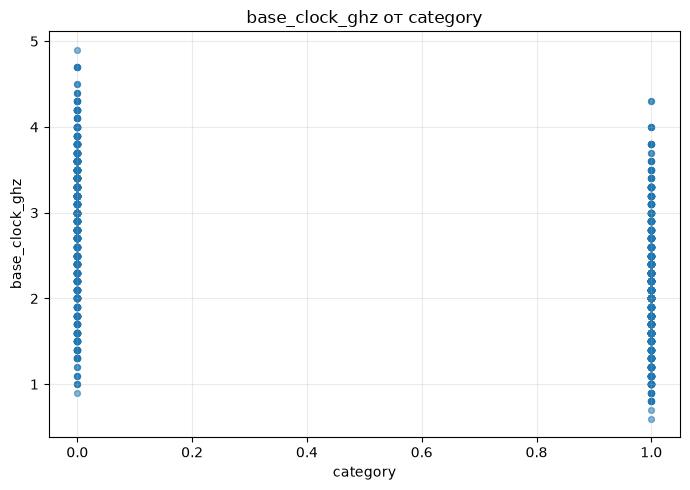

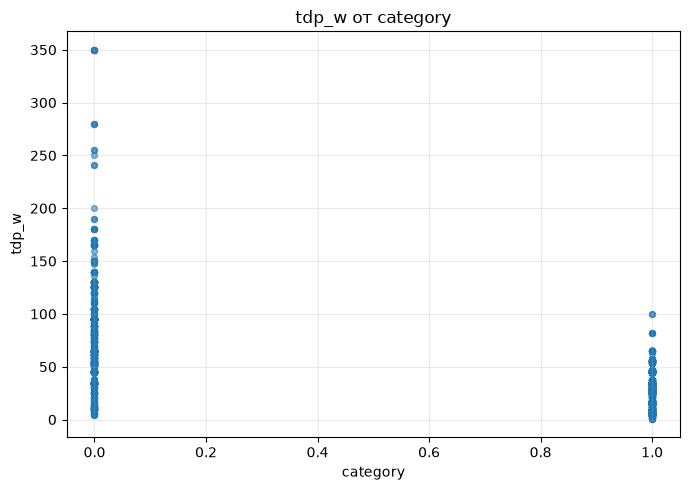

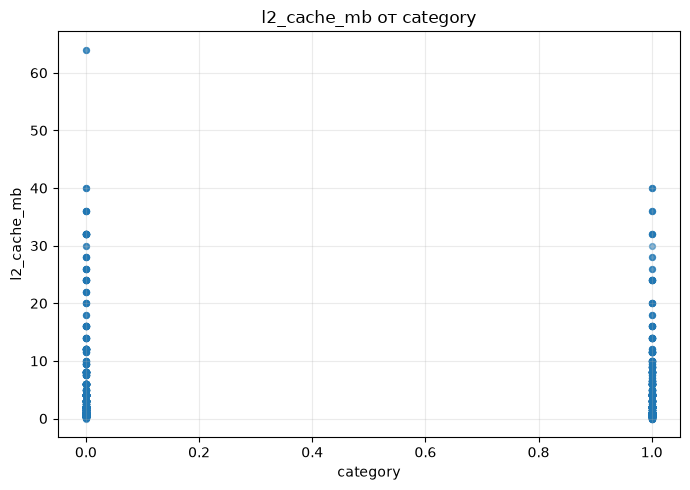

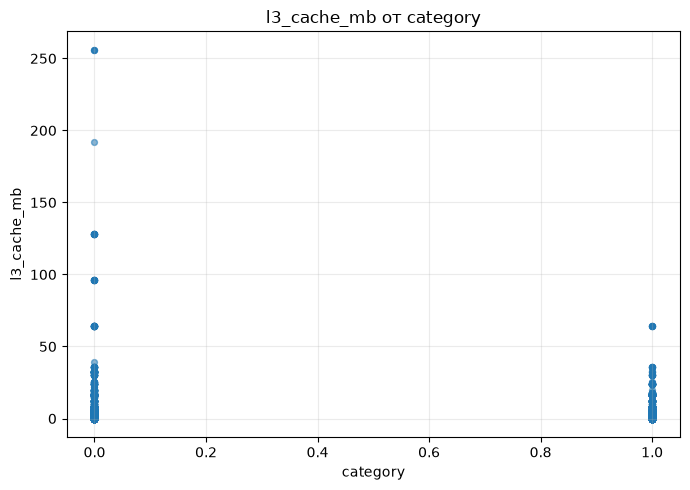

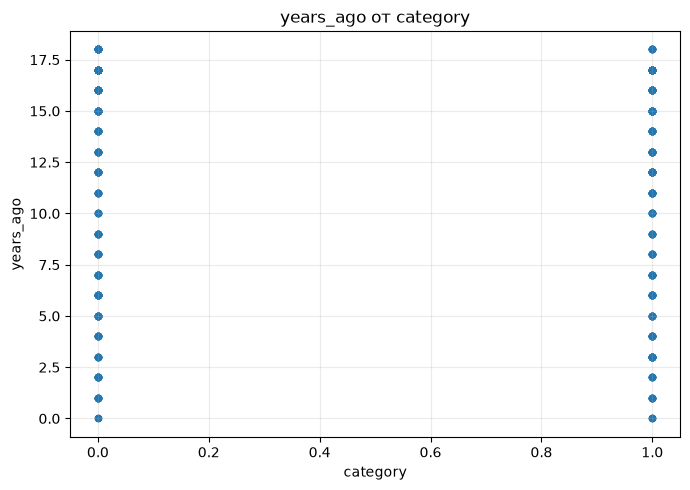

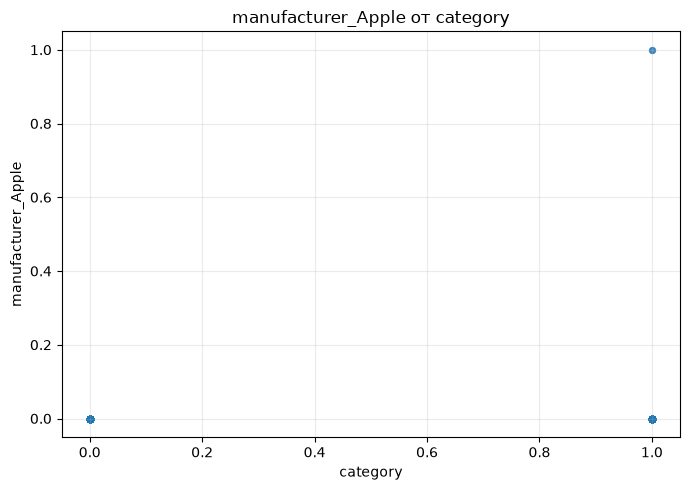

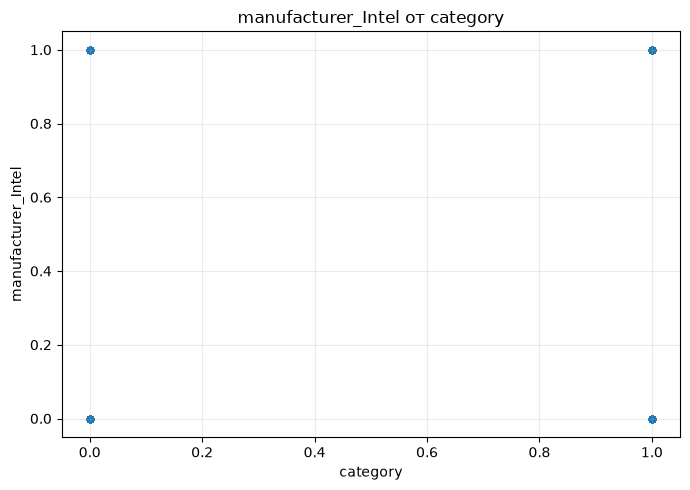

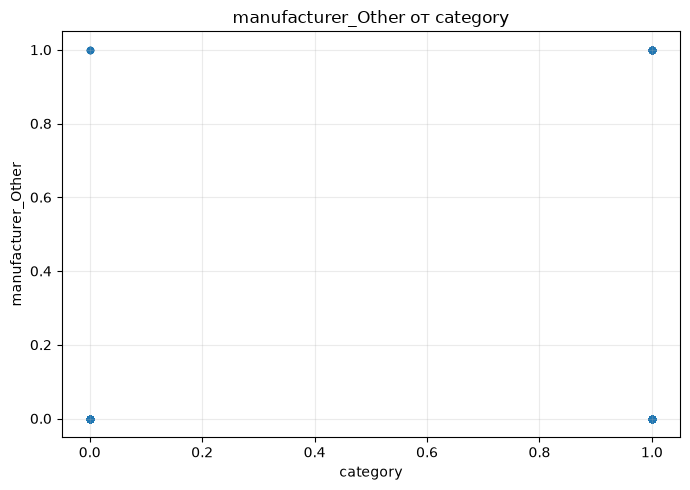

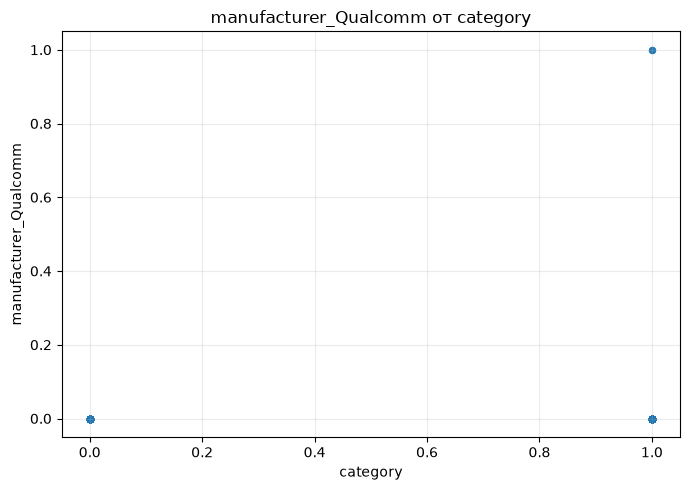

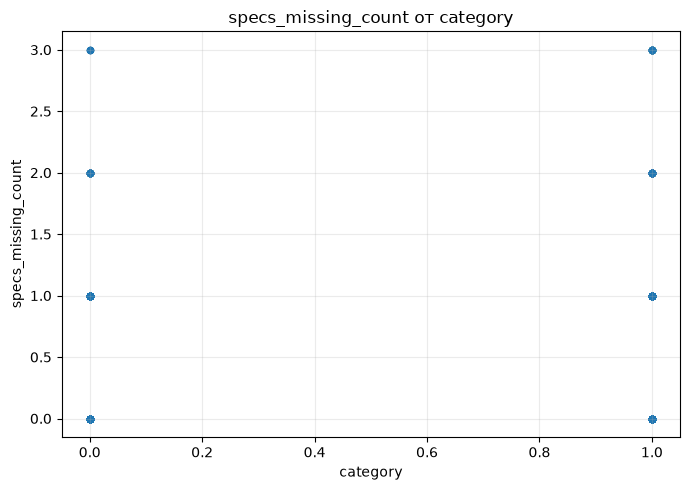

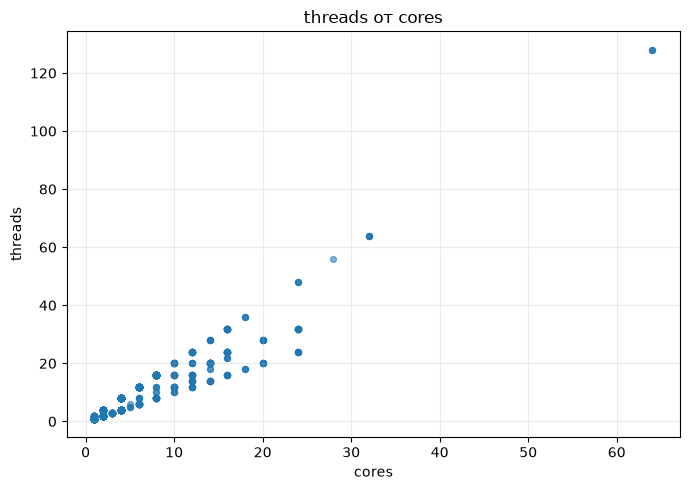

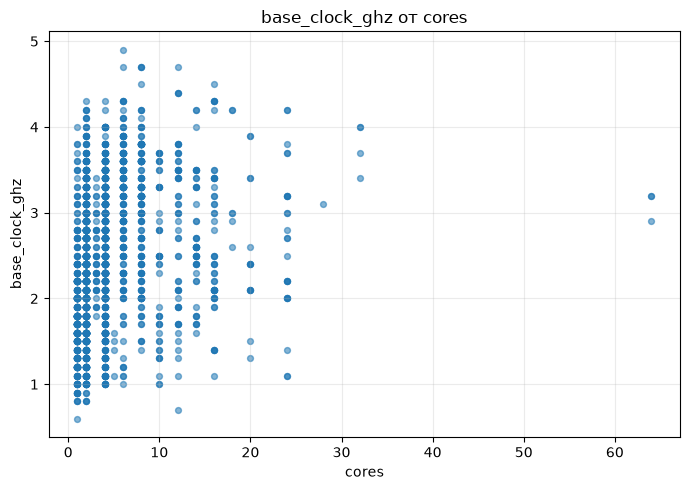

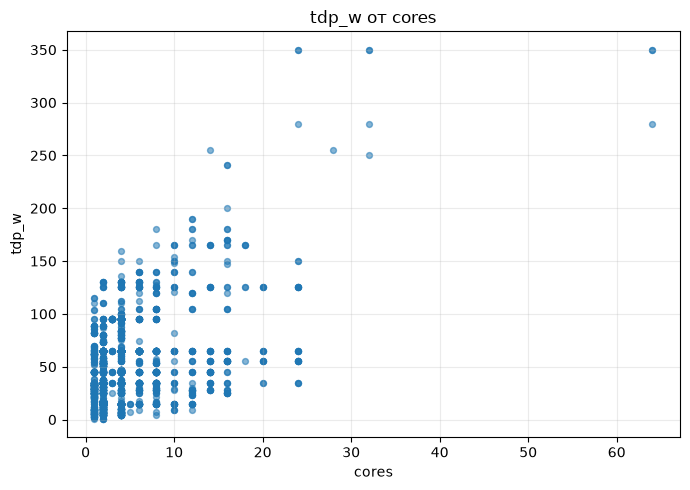

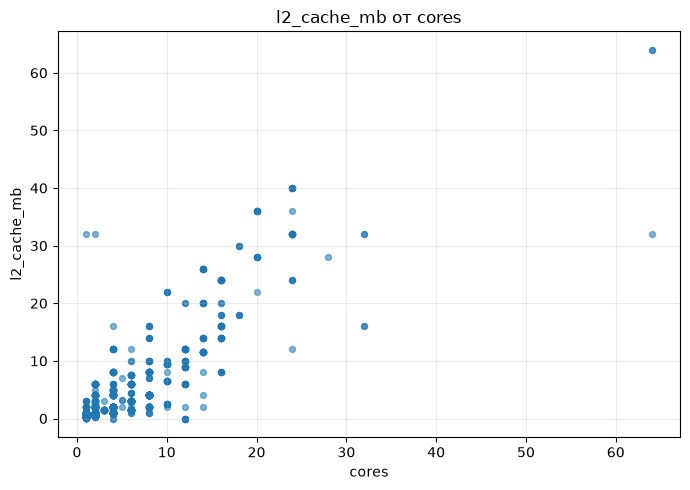

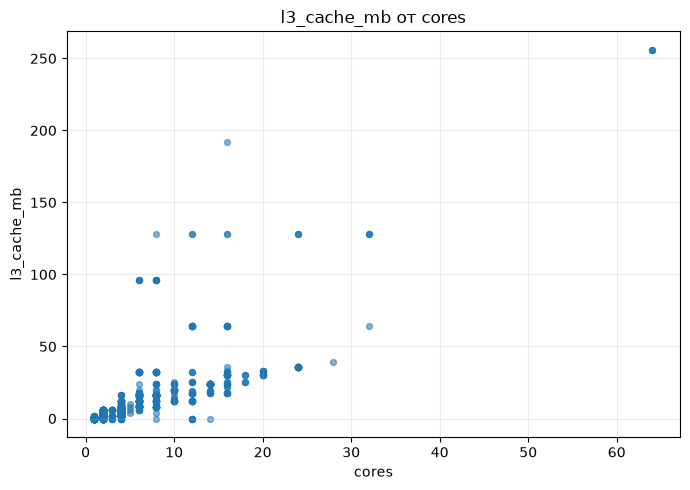

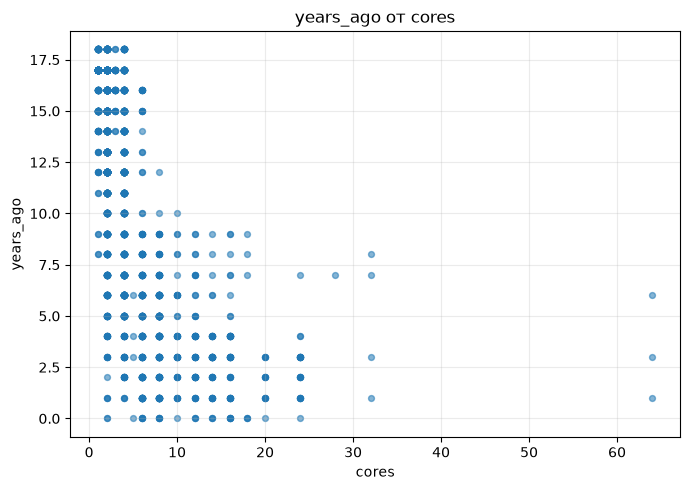

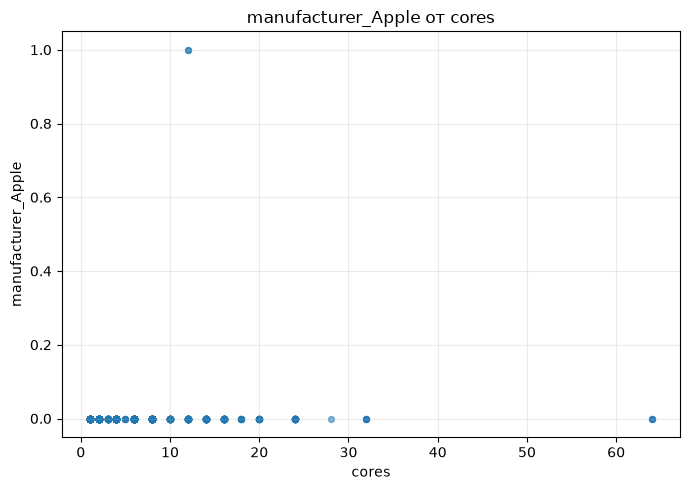

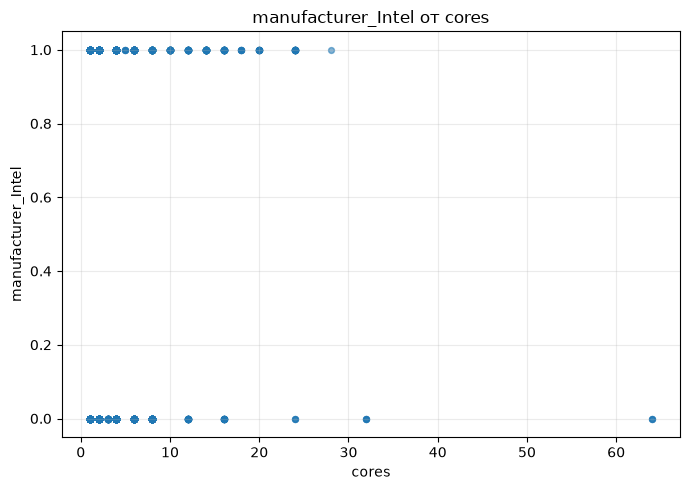

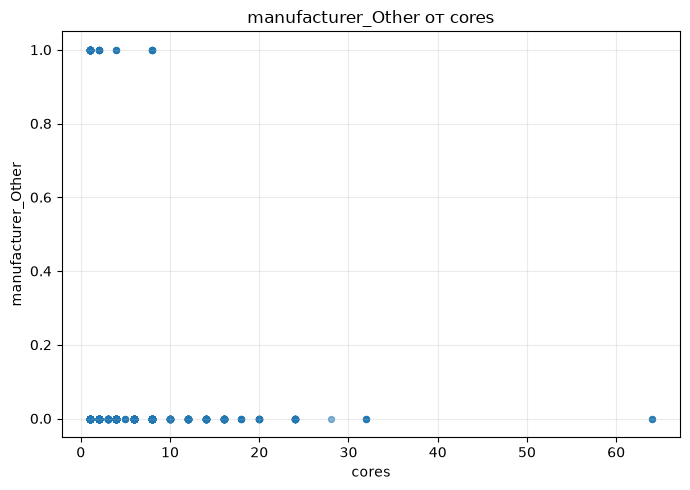

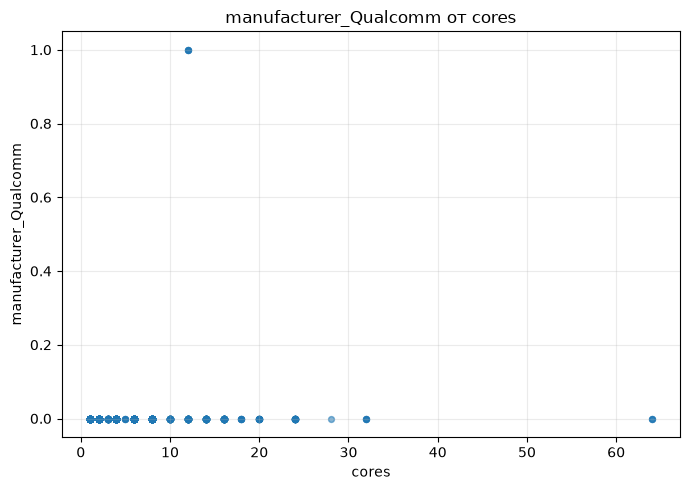

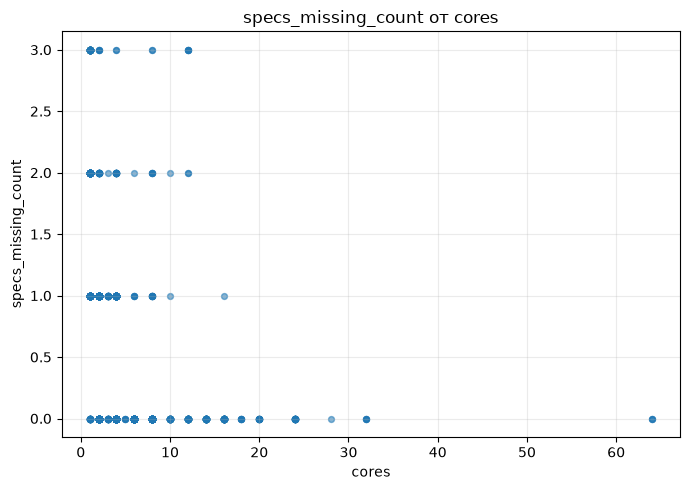

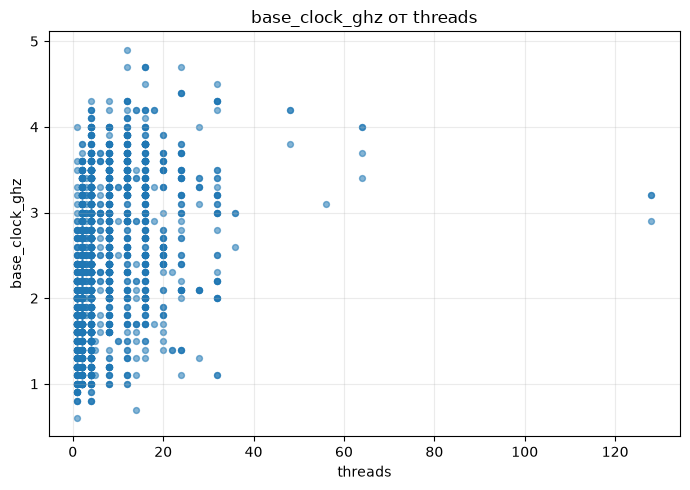

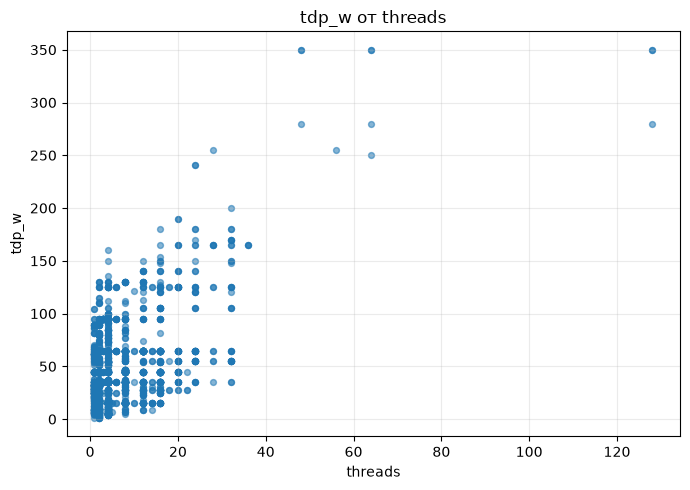

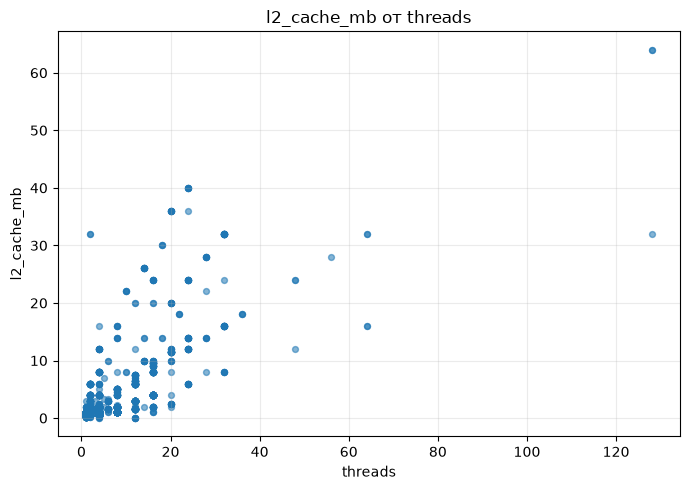

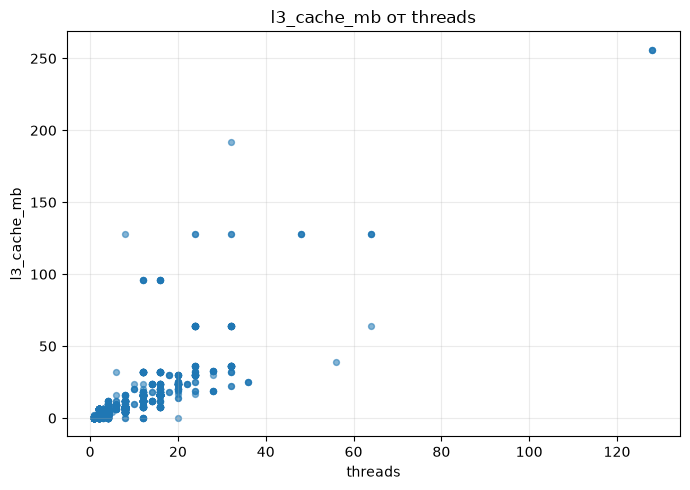

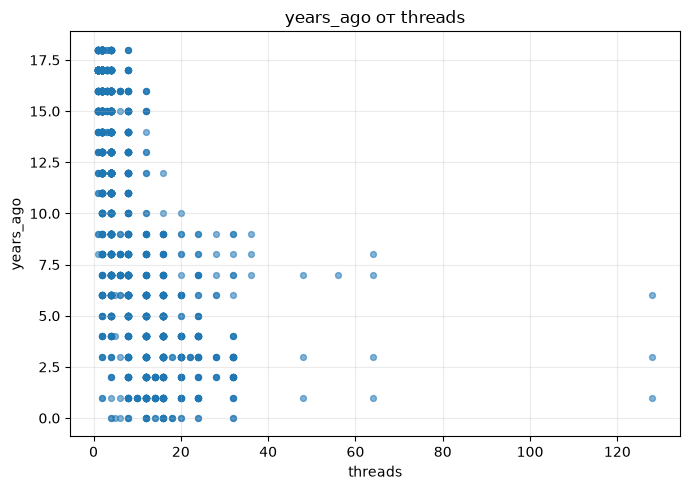

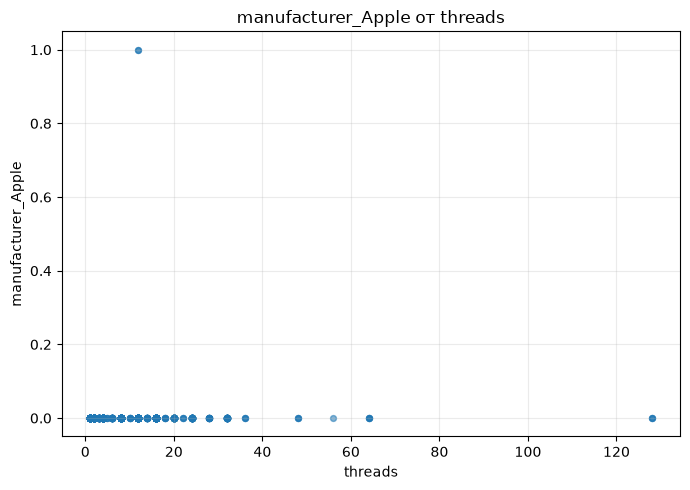

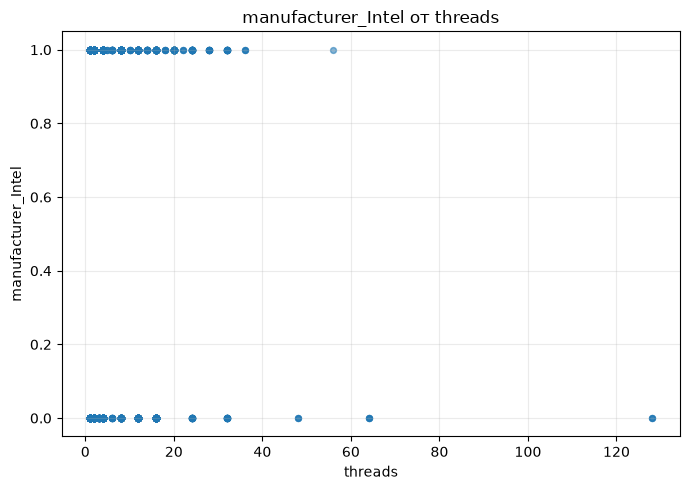

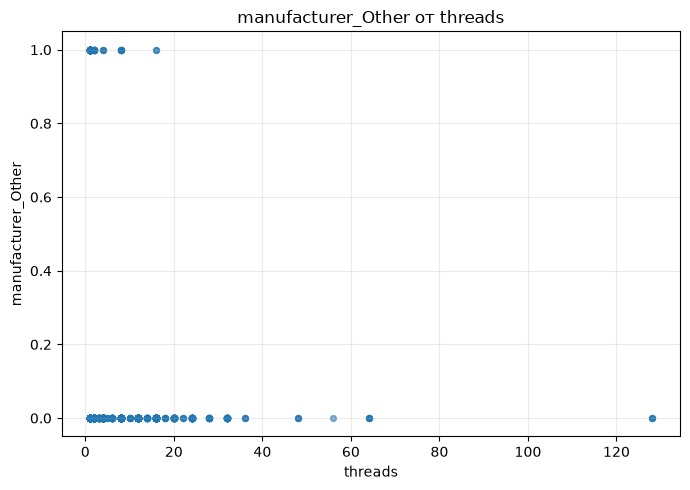

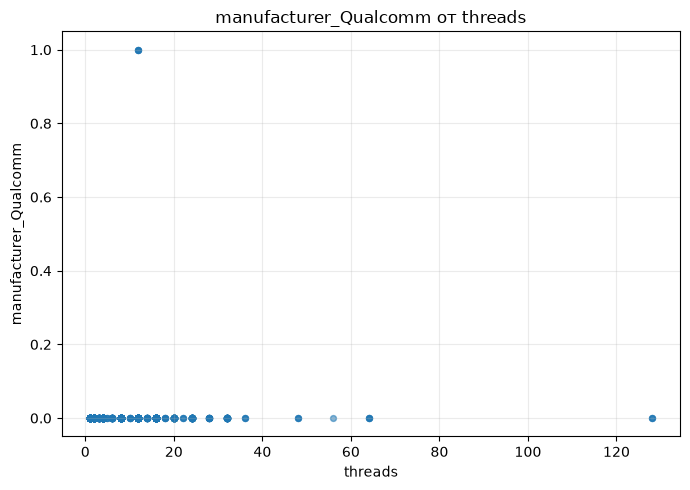

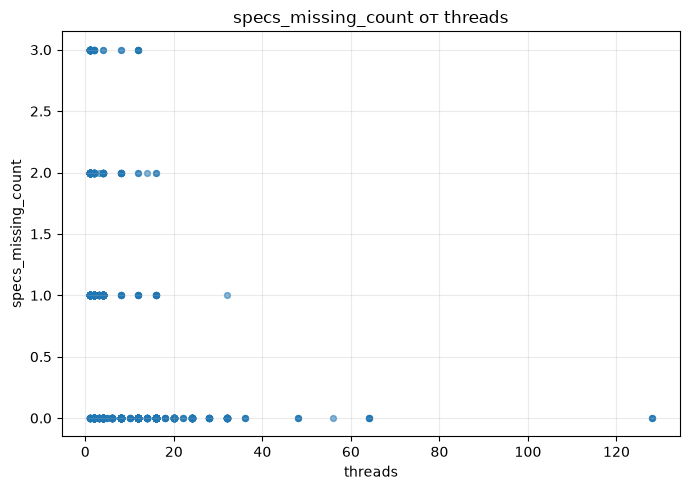

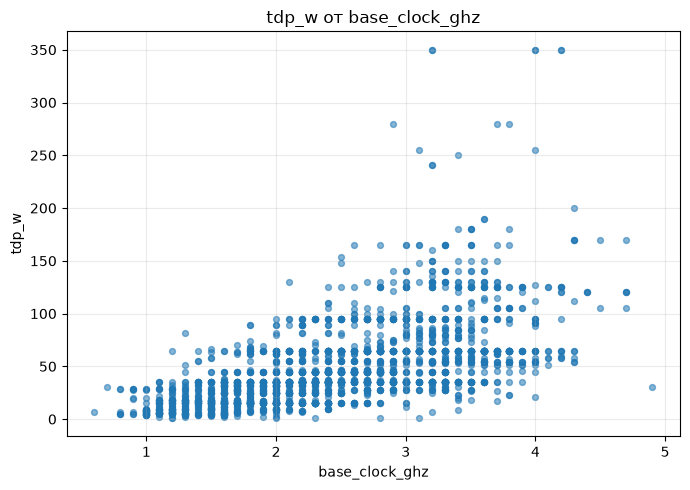

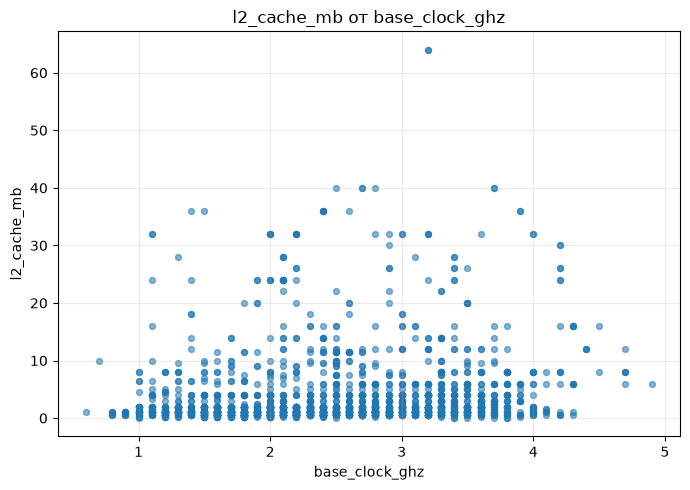

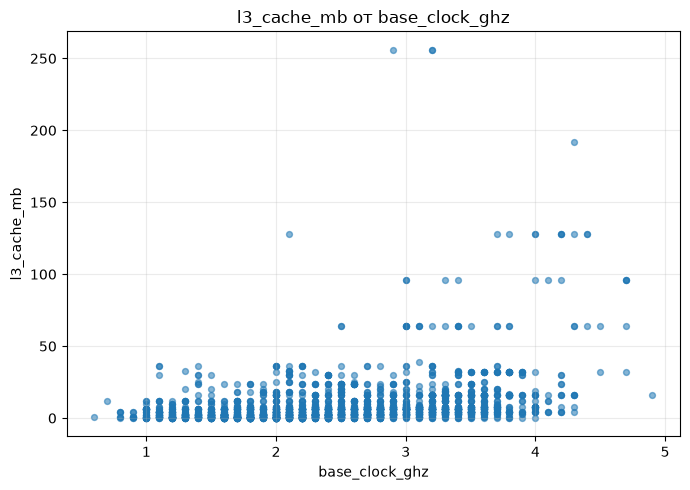

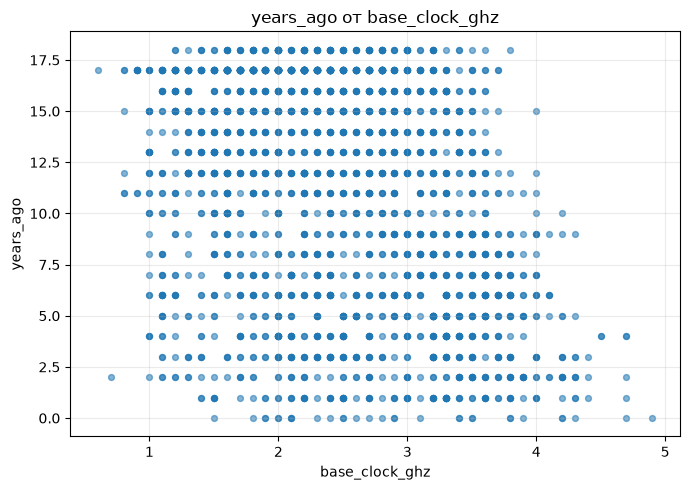

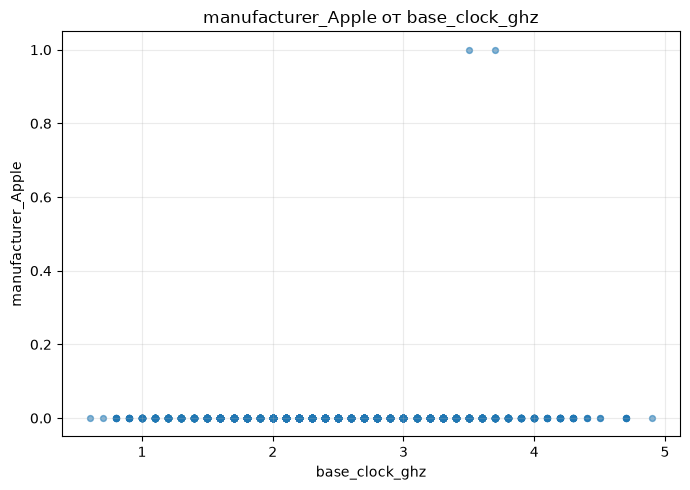

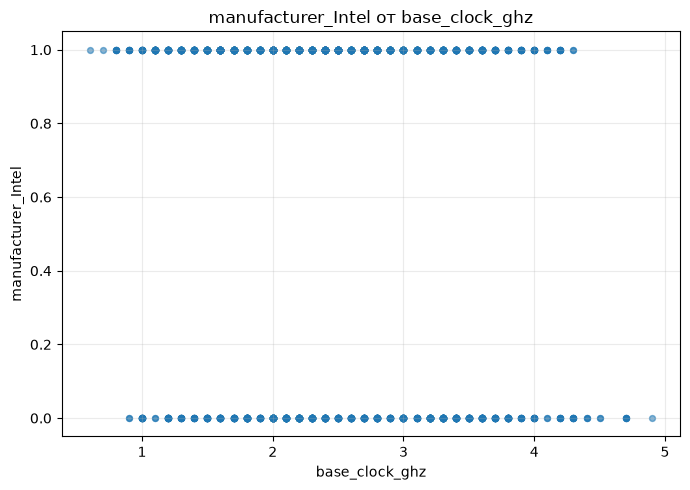

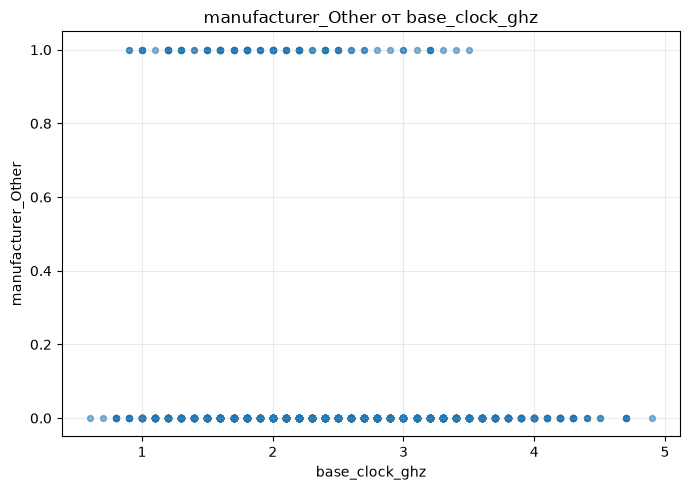

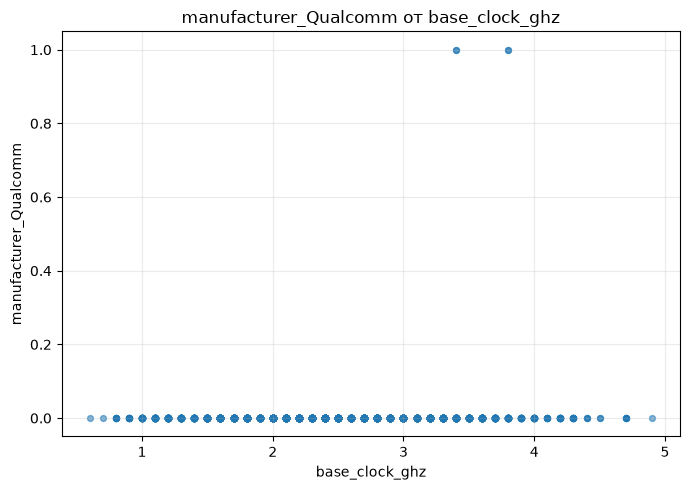

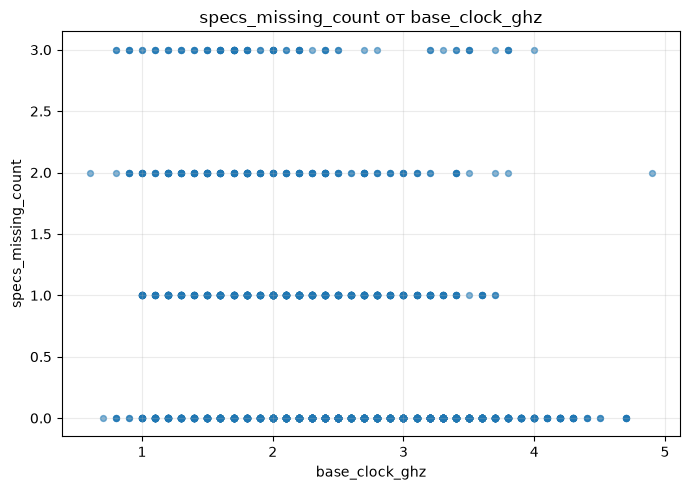

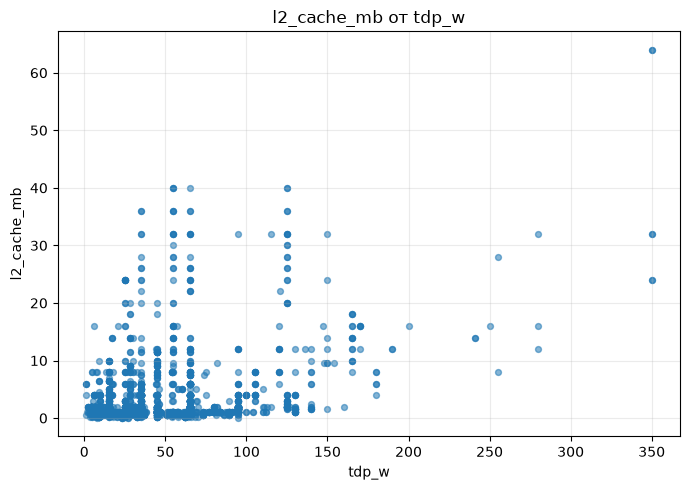

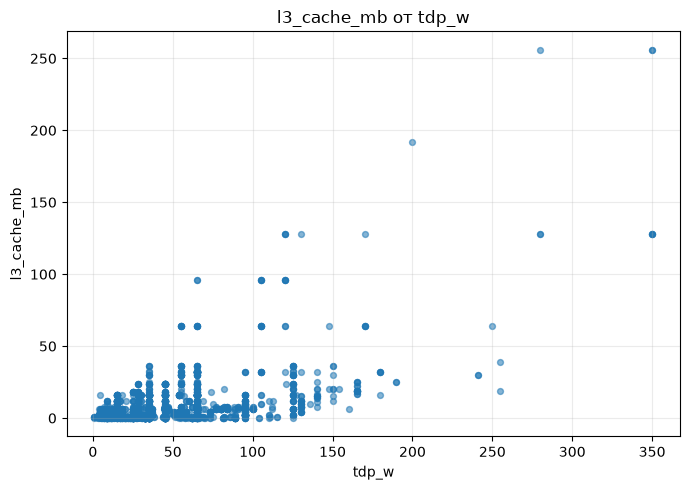

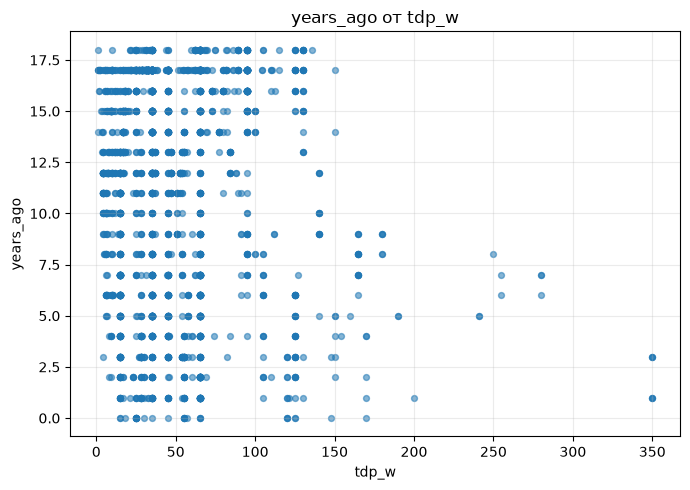

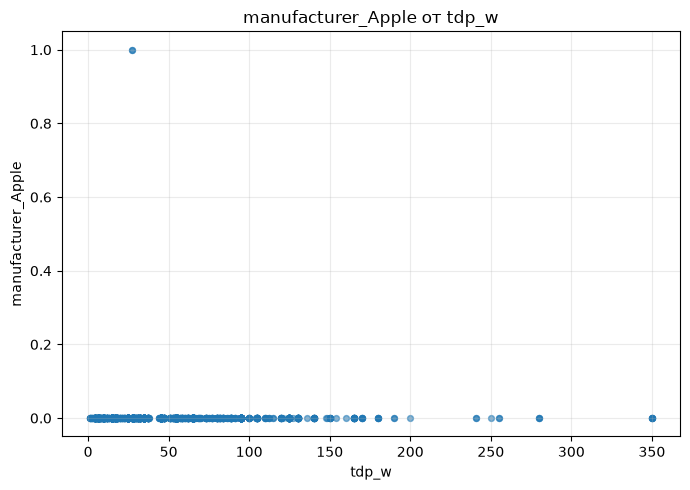

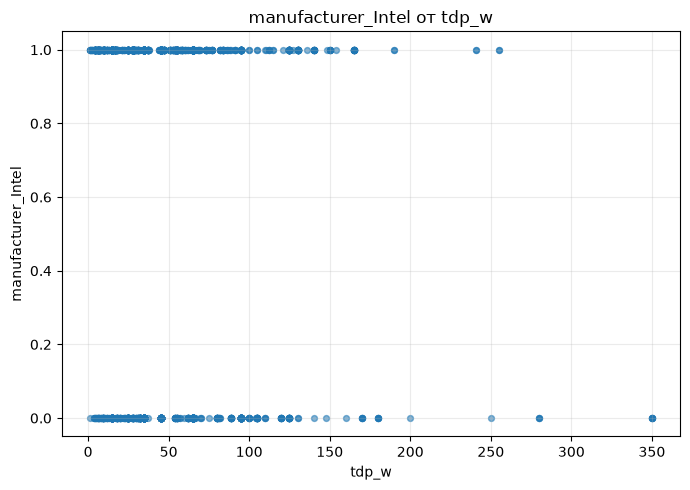

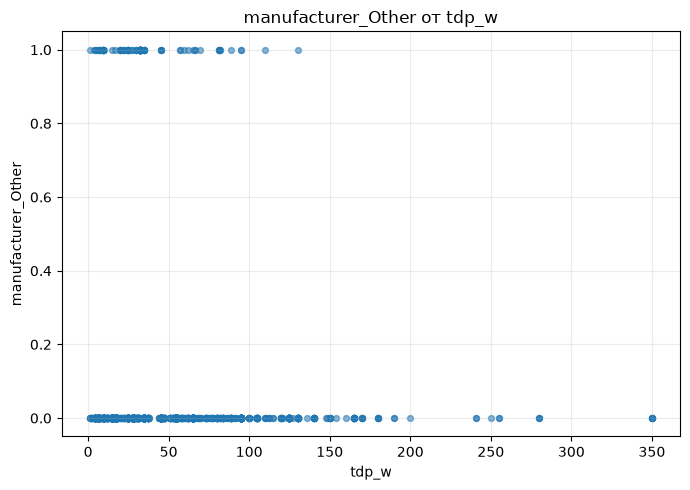

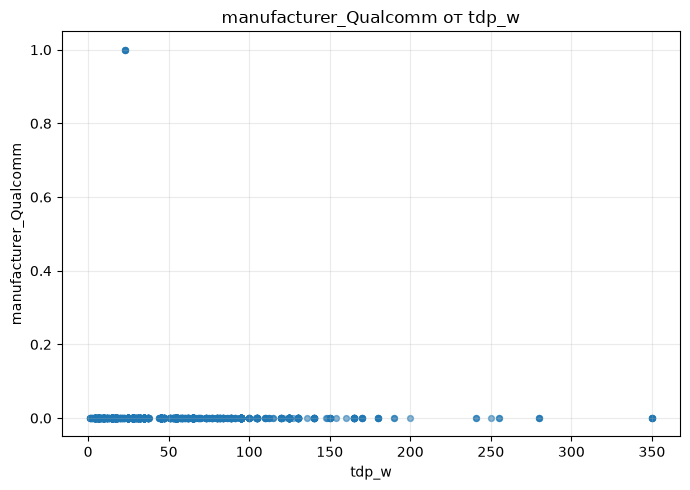

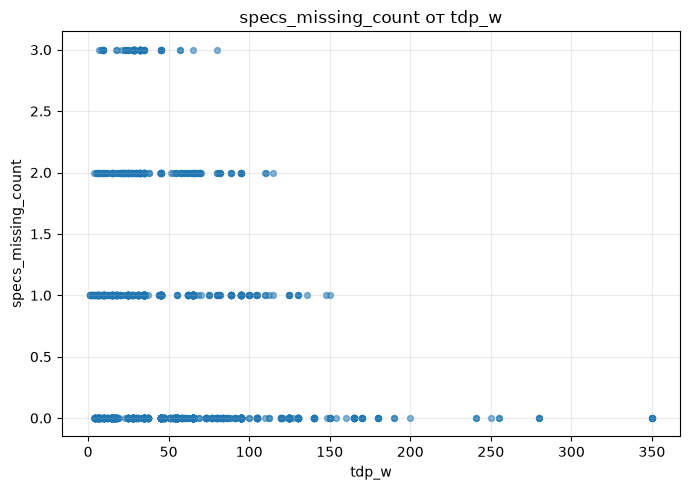

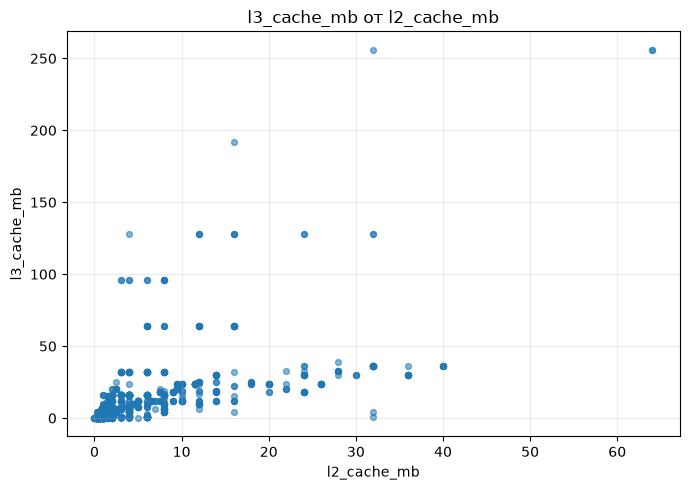

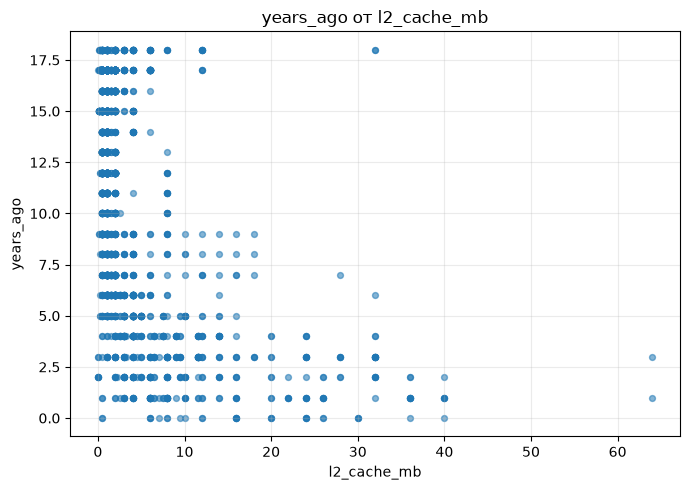

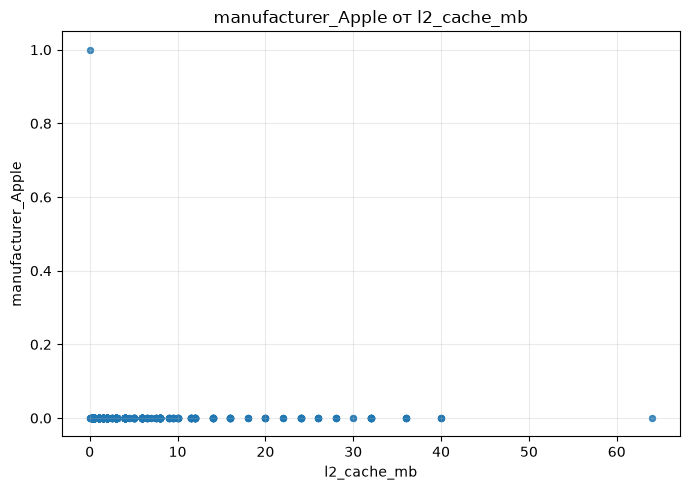

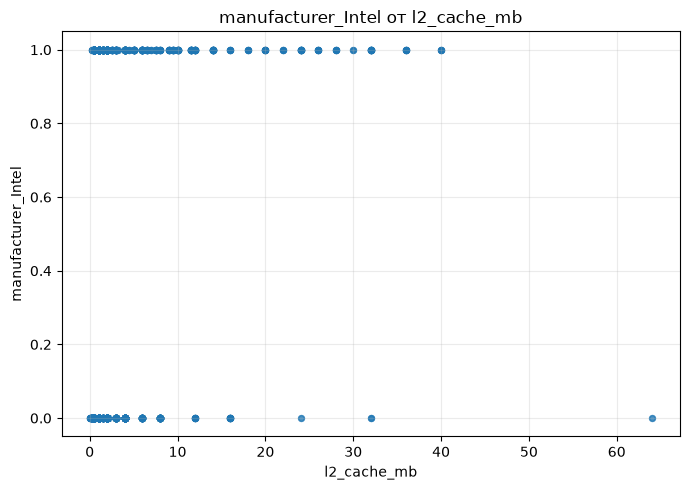

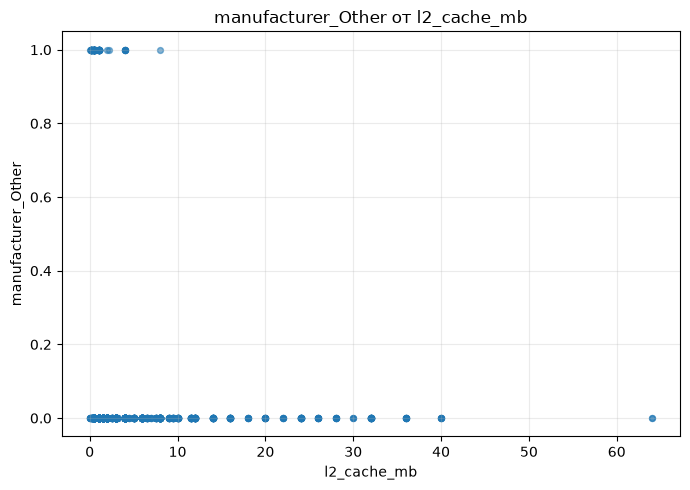

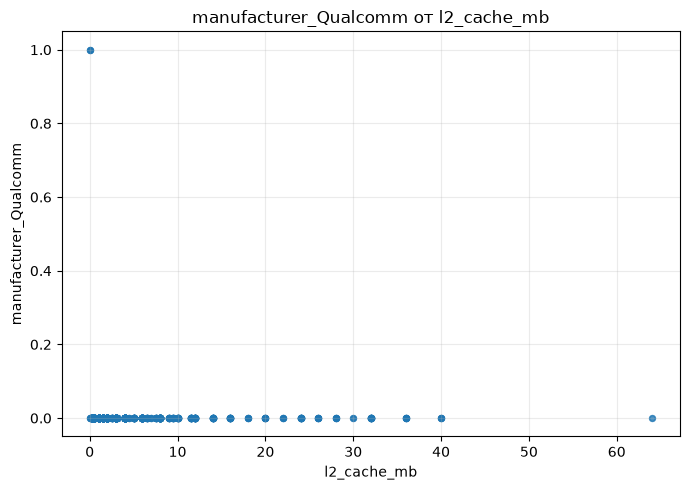

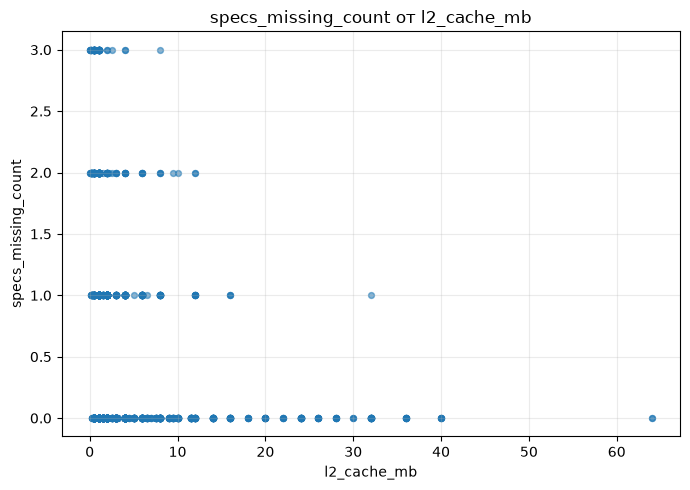

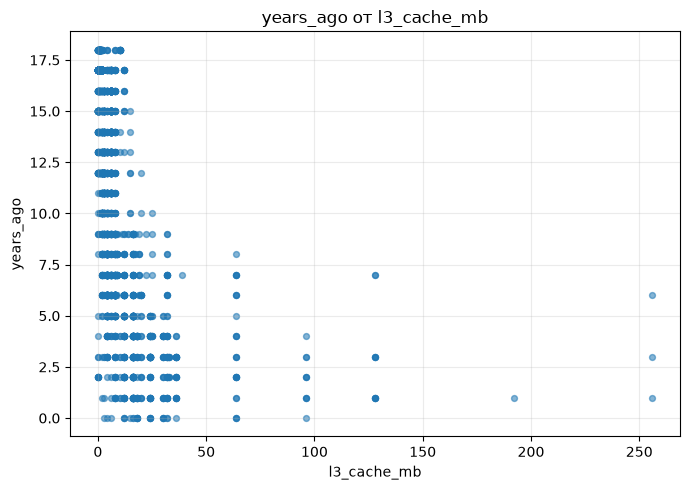

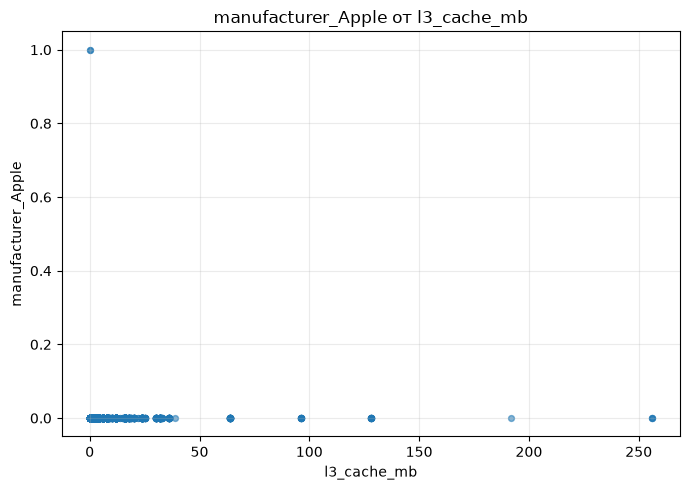

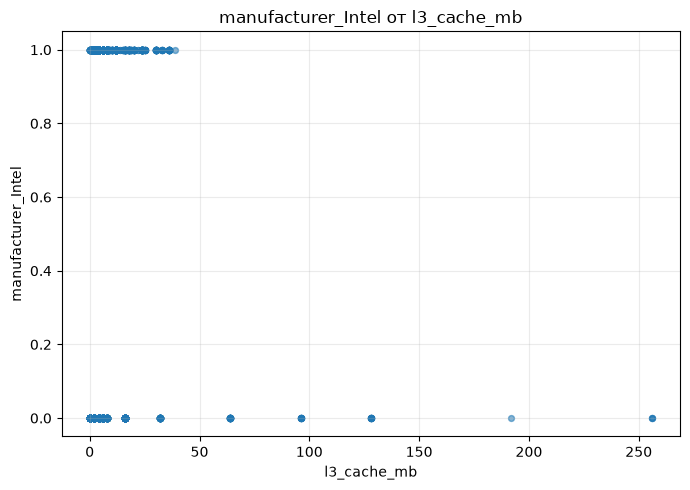

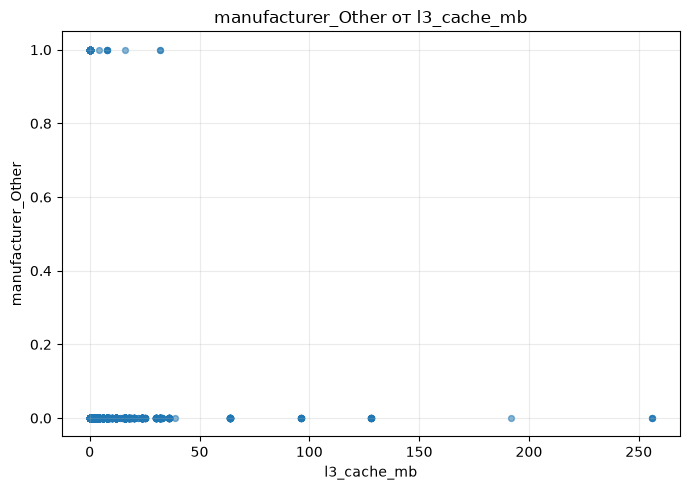

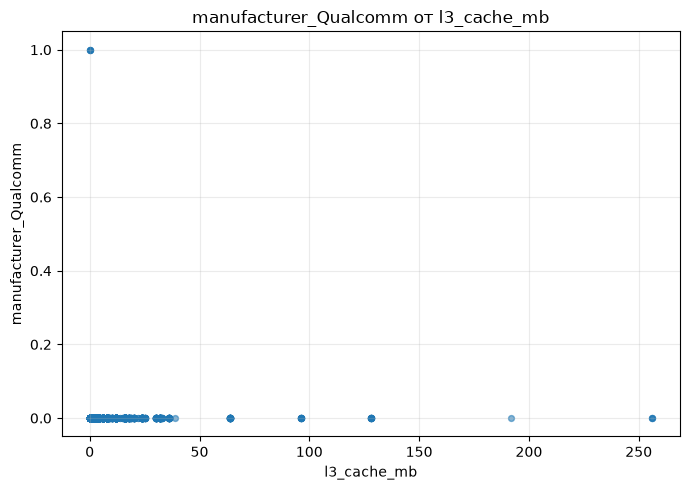

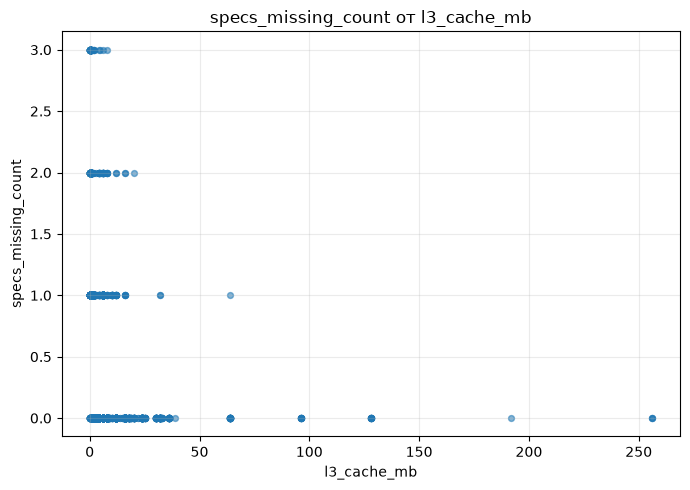

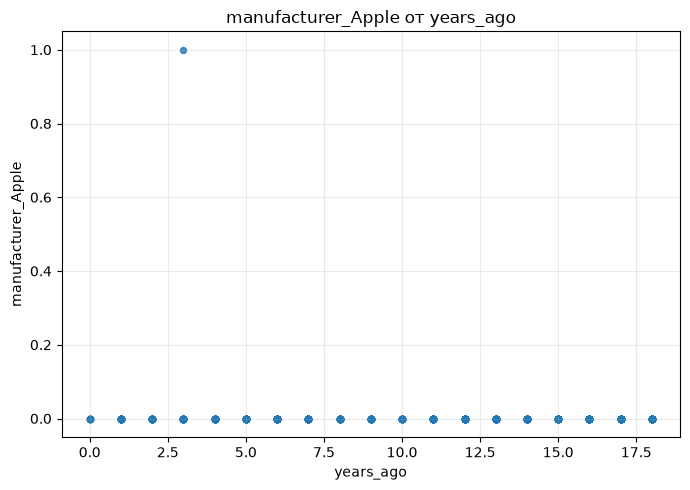

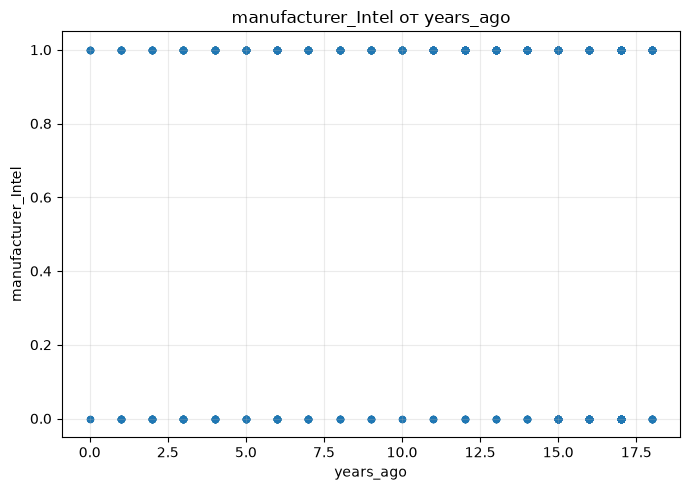

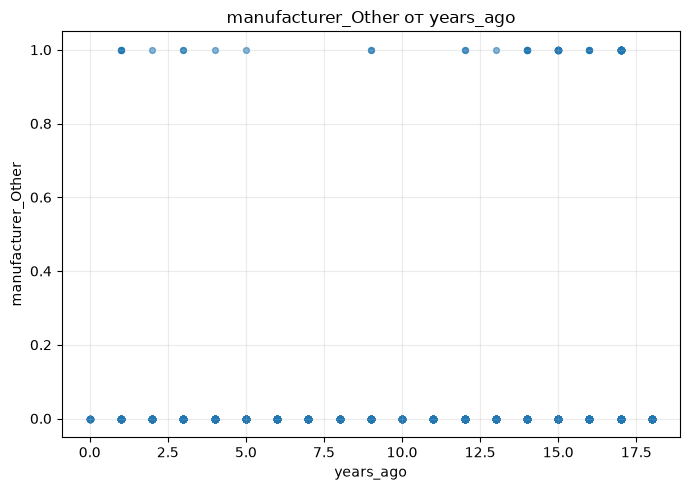

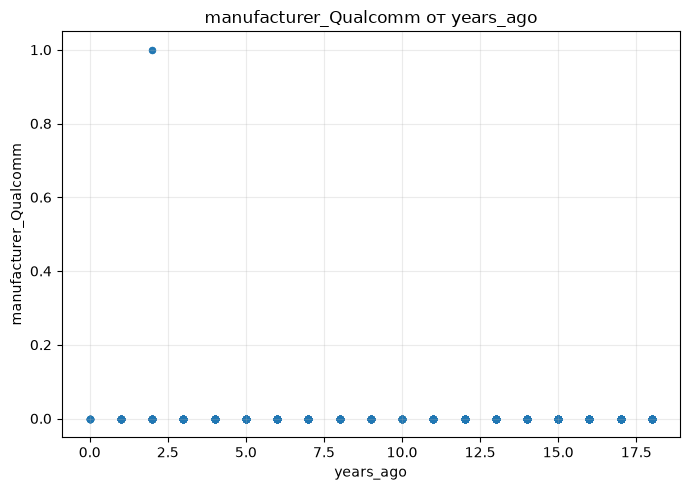

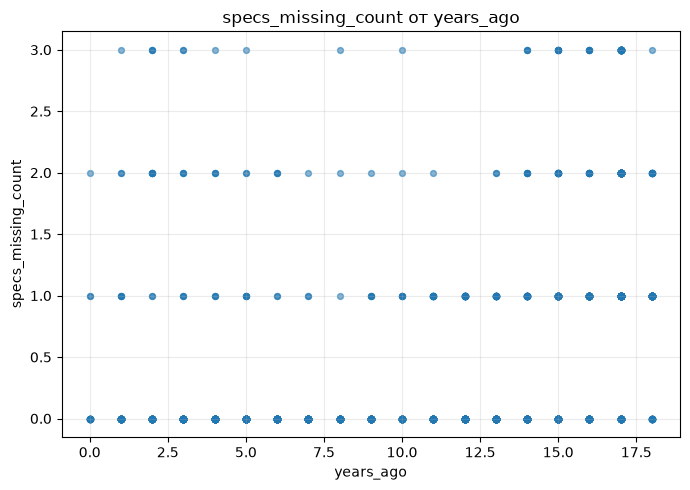

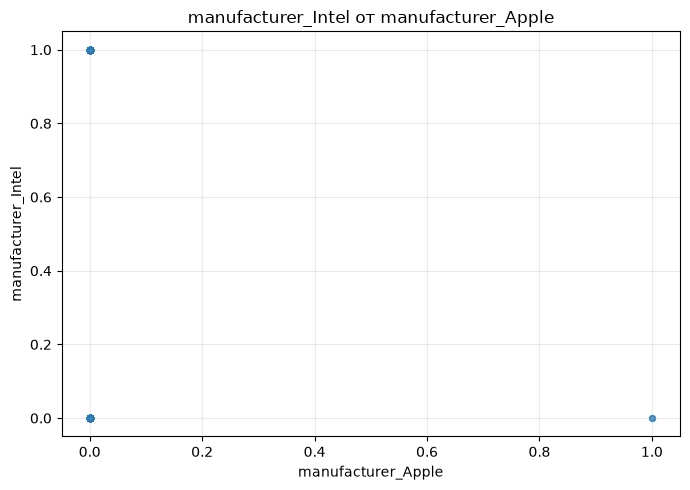

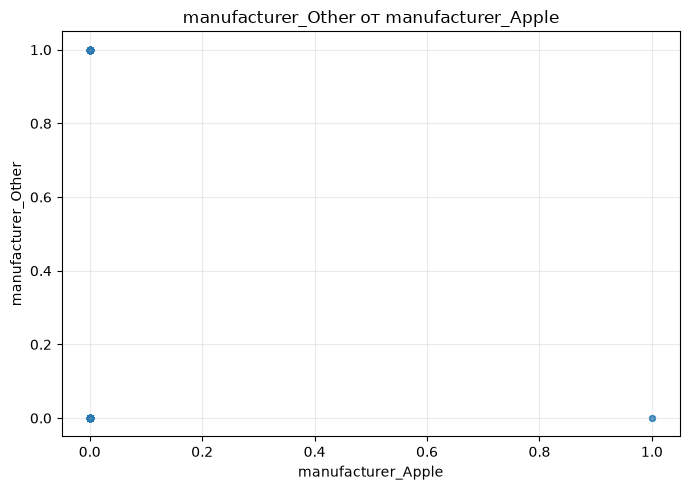

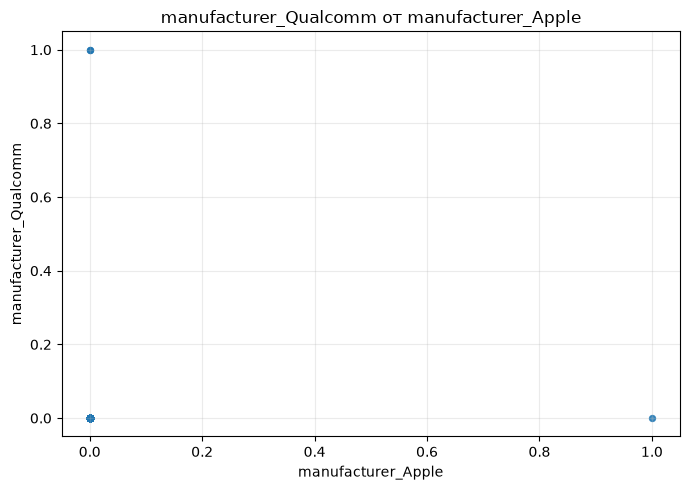

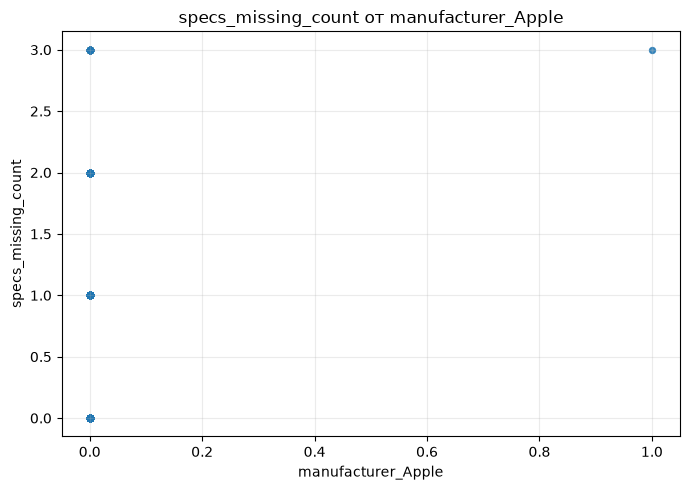

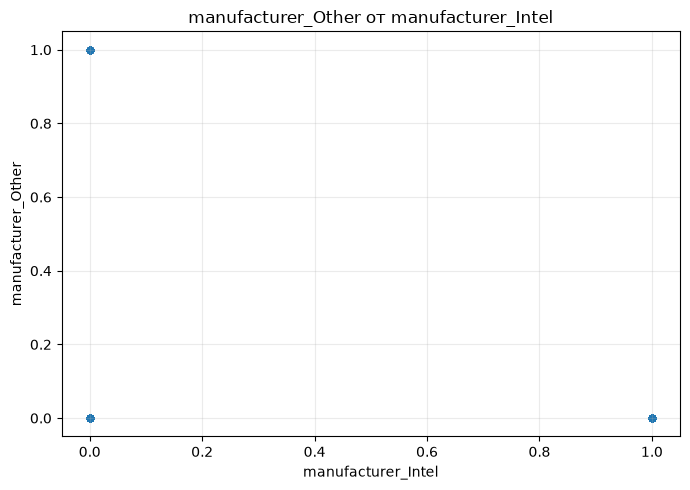

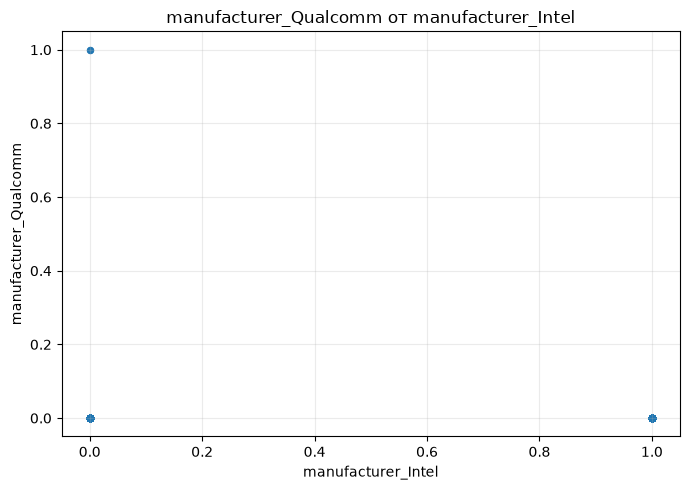

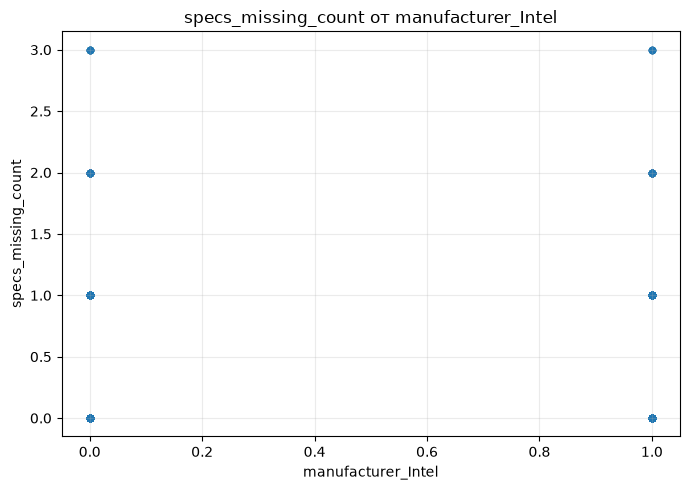

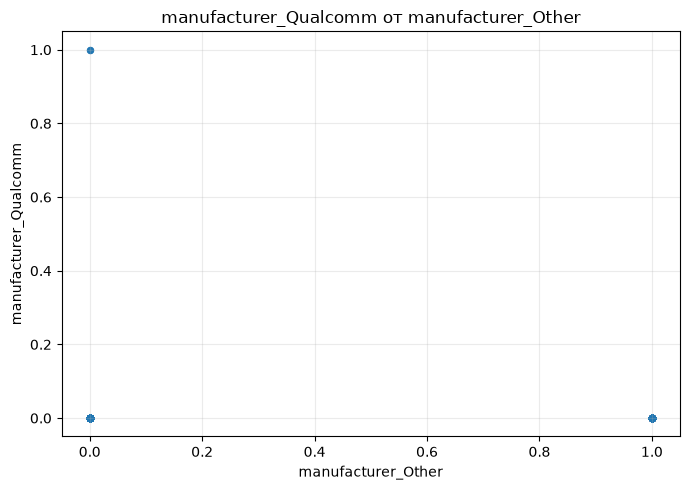

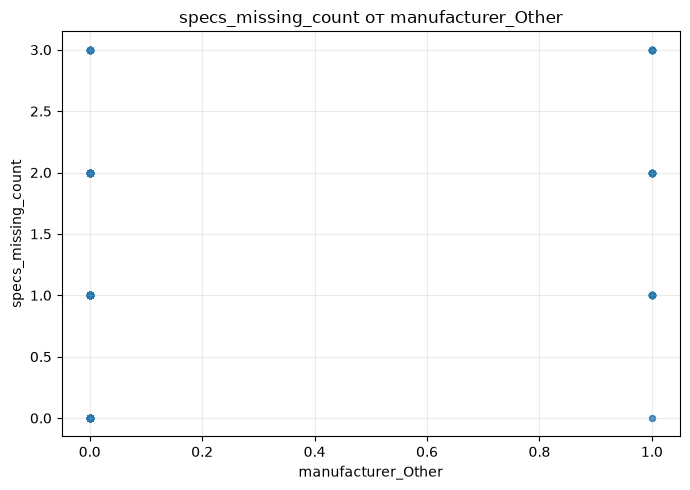

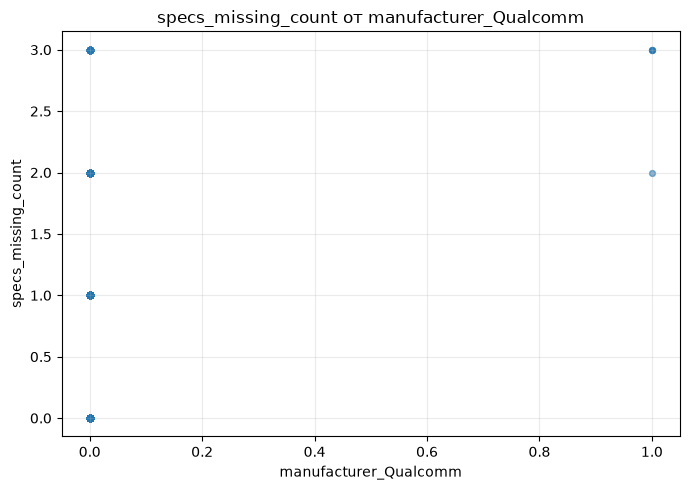

In [22]:
for x_col, y_col in combinations(features, 2):
    plot_data = df[[x_col, y_col]].dropna()

    plt.figure(figsize=(7, 5))
    plt.scatter(
        plot_data[x_col],
        plot_data[y_col],
        alpha=0.55,
        s=18,
    )
    plt.title(f"{y_col} от {x_col}")
    plt.xlabel(x_col)
    plt.ylabel(y_col)
    plt.grid(True, alpha=0.25)
    plt.tight_layout()
    plt.show()


In [41]:
import numpy as np
for feature in features:
    target = 'cpu_mark_log'
    df[f'{feature}_log'] = np.log(df[feature] + 1)

In [42]:
features

['cores',
 'threads',
 'base_clock_ghz',
 'tdp_w',
 'l2_cache_mb',
 'l3_cache_mb',
 'years_ago']

In [43]:
del features[0]
del features[7]
del features[7]
del features[7]
del features[7]
del features[7]

IndexError: list assignment index out of range

In [44]:
features

['threads',
 'base_clock_ghz',
 'tdp_w',
 'l2_cache_mb',
 'l3_cache_mb',
 'years_ago']

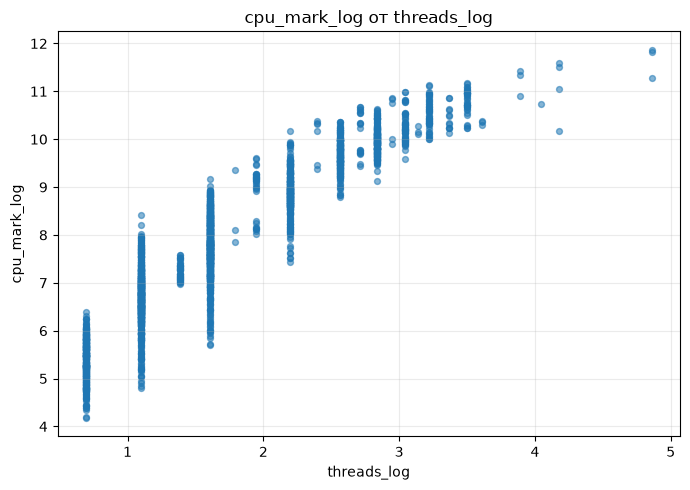

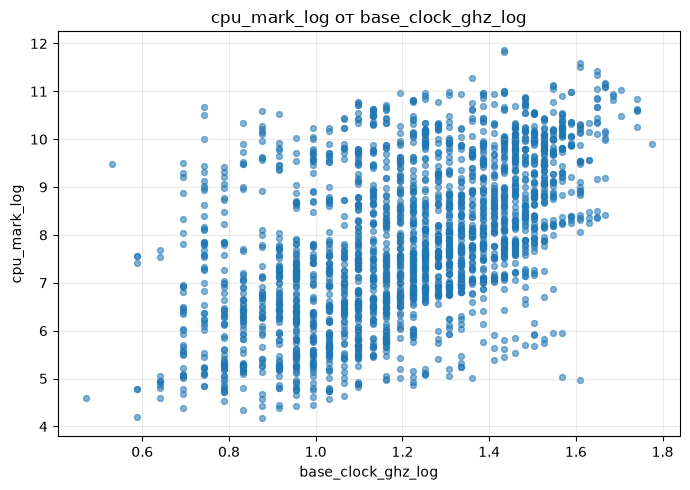

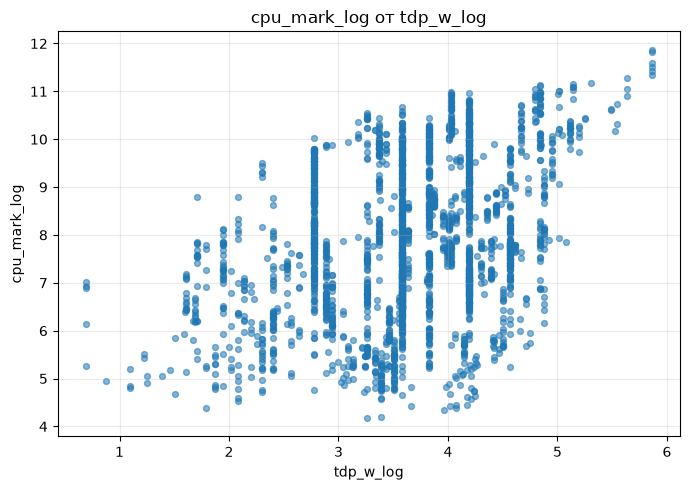

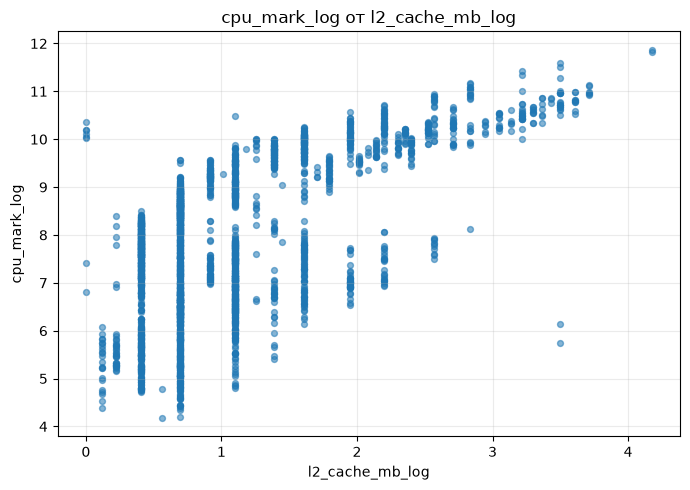

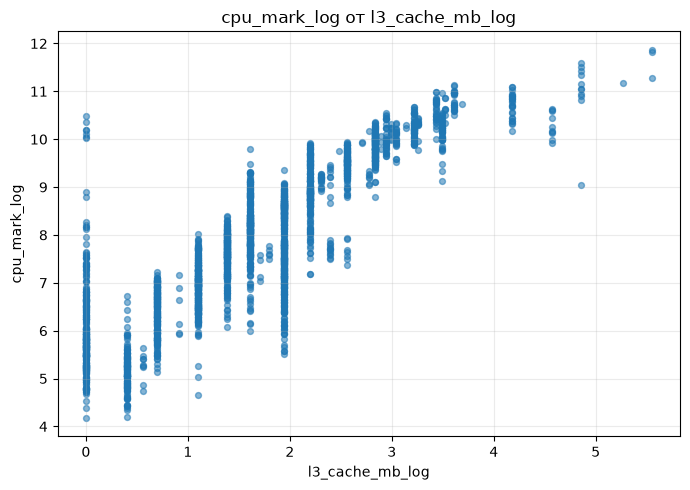

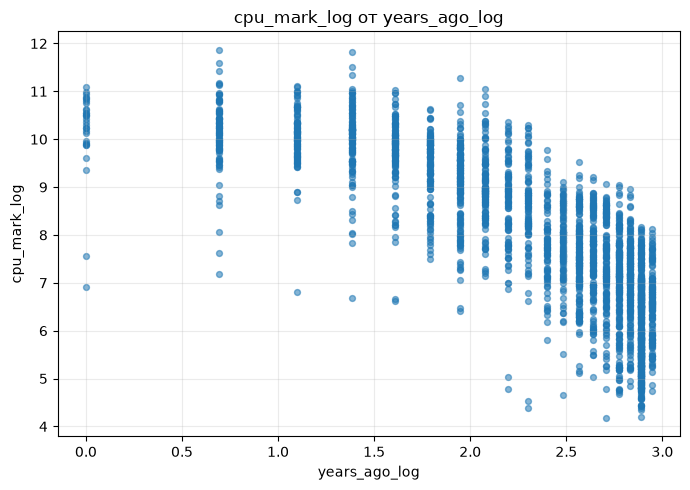

In [45]:
for feature in features:
    target = 'cpu_mark_log'
    feature = f'{feature}_log'
    plot_data = df[[feature, target]].dropna()

    plt.figure(figsize=(7, 5))
    plt.scatter(
        plot_data[feature],
        plot_data[target],
        alpha=0.55,
        s=18,
    )
    plt.title(f"{target} от {feature}")
    plt.xlabel(feature)
    plt.ylabel(target)
    plt.grid(True, alpha=0.25)
    plt.tight_layout()
    plt.show()


## 4. Краткая сводка

Эта ячейка не создаёт дополнительную сетку графиков, а просто показывает базовую описательную статистику для числовых данных.


In [28]:
display(df.describe().T)


,count,mean,std,min,25%,50%,75%,max
category,2623.0,0.511247,0.499969,0.000000,0.000000,1.000000,1.000000,1.000000
cores,2623.0,4.426611,4.691701,1.000000,2.000000,3.000000,4.000000,64.000000
threads,2623.0,6.771254,8.157413,1.000000,2.000000,4.000000,8.000000,128.000000
base_clock_ghz,2623.0,2.473084,0.787284,0.600000,1.900000,2.400000,3.100000,4.900000
tdp_w,2623.0,48.485799,37.947203,1.000000,25.000000,35.000000,65.000000,350.000000
l2_cache_mb,2623.0,3.432901,5.880459,0.000000,1.000000,1.000000,3.000000,64.000000
l3_cache_mb,2623.0,8.580919,16.281121,0.000000,2.000000,4.000000,8.000000,256.000000
cpu_mark,2623.0,7883.996569,12444.760086,65.000000,812.500000,2363.000000,9662.500000,142724.000000
years_ago,2623.0,11.017156,5.430591,0.000000,6.000000,12.000000,16.000000,18.000000
manufacturer_Apple,2623.0,0.000762,0.027608,0.000000,0.000000,0.000000,0.000000,1.000000
